# Task 1 — Error-context EDA and dataset v2

One linear notebook creates exactly one new saved dataset, `eda_error_context_v2`. The analysis uses labeled Train and existing out-of-fold (OOF) predictions only. Test is read only to apply deterministic row-wise formulas and check output schema. No target-derived aggregate or Test-fitted statistic enters the features. The eight new candidate columns are separated into context and behavior groups for model ablation.

In [1]:
from pathlib import Path
import json
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.pipeline.random_seed import set_seed
from src.pipeline.save_data import save_data
SEED = set_seed()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
SRC = ROOT / "src"
TASK = SRC / "task1"
RAW = TASK / "data" / "raw"
TARGET, ID = "is_cheater", "player_id"
NAME = "eda_error_context_v2"
train_raw = pd.read_csv(RAW / "train.csv")
test_raw = pd.read_csv(RAW / "test.csv")
assert TARGET in train_raw and TARGET not in test_raw
assert train_raw.columns.drop(TARGET).tolist() == test_raw.columns.tolist()
assert train_raw[ID].is_unique and test_raw[ID].is_unique
assert not set(train_raw[ID]) & set(test_raw[ID])
raw_features = test_raw.columns.drop(ID).tolist()
assert len(raw_features) == 31
train = train_raw.loc[train_raw[TARGET].notna()].copy().reset_index(drop=True)
train[TARGET] = train[TARGET].astype("int8")
assert len(train) == 90816 and train[TARGET].isin([0,1]).all()
print("Labeled Train:", len(train), "unlabeled rows excluded:", len(train_raw)-len(train))
print("Test rows retained for final artifact:", len(test_raw))

Labeled Train: 90816 unlabeled rows excluded: 13184
Test rows retained for final artifact: 25889


## 1. Link existing held-out errors to raw accounts

The selected full-data LightGBM was trained on all labeled rows, so its in-sample predictions are not suitable. Reuse the first OOF repeat, verify account and label alignment, and use repeat 2 later to check stability. This analysis does not fit a model.

In [2]:
old_card = json.loads((TASK / "data" / "eda" / "eda_combined_v1.json").read_text(encoding="utf-8"))
old_train = pd.read_parquet(SRC / old_card["splits"]["train"]["path"])
assert old_train[ID].equals(train[ID]) and old_train[TARGET].equals(train[TARGET])
oof_dir = TASK / "models" / "results"
oof1 = pd.read_parquet(oof_dir / "round4_lgbm_combined_pruned_oof_v1.parquet").sort_values("row_index").reset_index(drop=True)
oof2 = pd.read_parquet(oof_dir / "round4_lgbm_combined_pruned_repeat2_oof_v1.parquet").sort_values("row_index").reset_index(drop=True)
for oof in (oof1, oof2):
    assert np.array_equal(oof.row_index, np.arange(len(train)))
    assert oof[ID].equals(train[ID]) and oof.true.equals(train[TARGET].astype(int))
    assert (oof.pred == (oof.prob >= oof.threshold).astype(int)).all()
errors = train[[ID,TARGET,"reports_received","friend_network_size","account_age_days",
                "sessions_per_day","kill_death_ratio","headshot_percentage",
                "crosshair_placement","aiming_smoothness","kill_consistency",
                "input_consistency_score"]].copy()
errors["prob"] = oof1.prob
errors["margin"] = oof1.prob-oof1.threshold
errors["pred"] = oof1.pred
errors["wrong_r1"] = oof1.pred.ne(oof1.true)
errors["wrong_r2"] = oof2.pred.ne(oof2.true)
errors["persistent_wrong"] = errors.wrong_r1 & errors.wrong_r2
errors["type"] = np.select([(errors[TARGET].eq(0)&errors.pred.eq(1)),
                             (errors[TARGET].eq(1)&errors.pred.eq(0))],
                            ["FP","FN"],default="correct")
display(errors.groupby("type").agg(accounts=(ID,"size"),persistent=("persistent_wrong","sum"),
                                   mean_prob=("prob","mean")).round(3))

,accounts,persistent,mean_prob
type,,,
FN,7470,5955,0.284
FP,11846,10148,0.520
correct,71500,0,0.327


## 2. Inspect report/social/account-age cells

For each cell, compare cheater prevalence, model probability, and class-conditional error. Large differences can suggest an interaction worth encoding. All bins are derived from labeled Train for analysis only; no bin label is saved as a model feature.

,report_bin,friend_bin,accounts,cheater_rate,mean_probability,error_rate
0,<=8,<=49,1116,0.907,0.893,0.020
1,<=8,50–105,3396,0.604,0.609,0.223
2,<=8,106–220,6060,0.433,0.433,0.292
3,<=8,>220,2492,0.445,0.444,0.195
4,<=8,Missing,3699,0.524,0.516,0.266
5,9–14,<=49,3595,0.392,0.396,0.160
6,9–14,50–105,4864,0.582,0.572,0.232
7,9–14,106–220,9374,0.381,0.376,0.307
8,9–14,>220,4453,0.335,0.336,0.212
9,9–14,Missing,6537,0.406,0.413,0.314


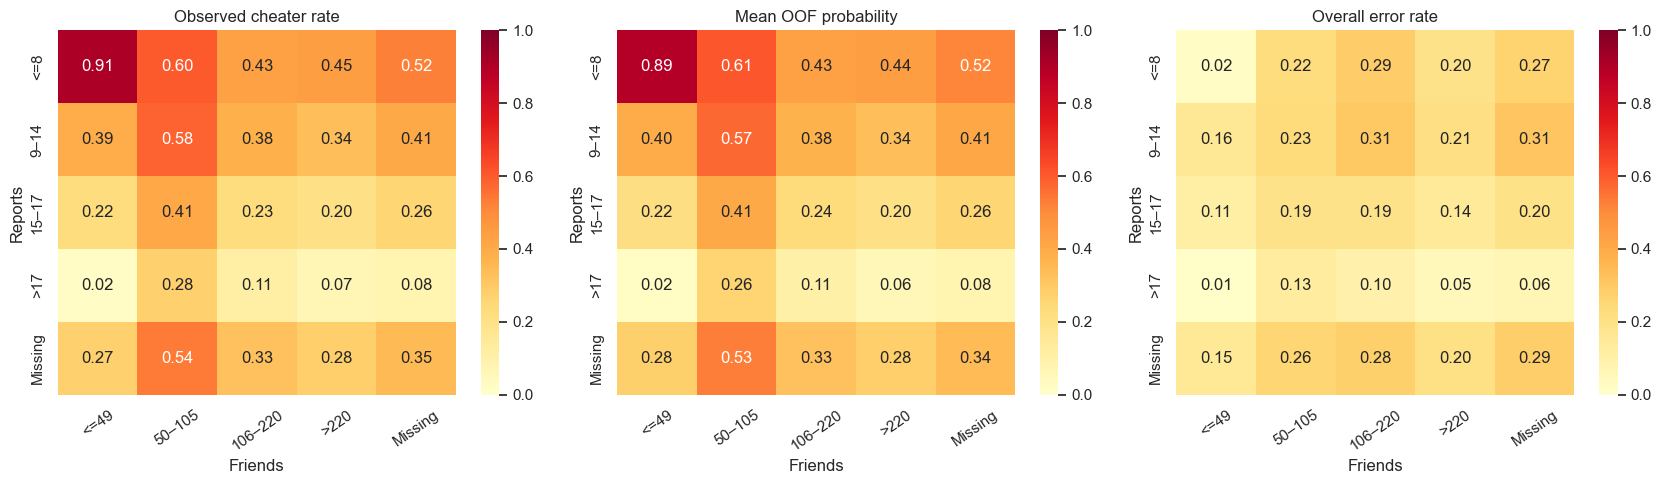

In [3]:
report_bins = pd.cut(errors.reports_received, [-np.inf,8,14,17,np.inf],
                     labels=["<=8","9–14","15–17",">17"]).cat.add_categories("Missing").fillna("Missing")
friend_bins = pd.cut(errors.friend_network_size, [-np.inf,49,105,220,np.inf],
                     labels=["<=49","50–105","106–220",">220"]).cat.add_categories("Missing").fillna("Missing")
errors["report_bin"], errors["friend_bin"] = report_bins, friend_bins
cells_report_friend = (errors.groupby(["report_bin","friend_bin"],observed=True)
                       .agg(accounts=(ID,"size"),cheater_rate=(TARGET,"mean"),
                            mean_probability=("prob","mean"),
                            error_rate=("wrong_r1","mean")).reset_index())
display(cells_report_friend.loc[cells_report_friend.accounts>=300].round(3))

fig, axes = plt.subplots(1, 3, figsize=(17,5))
for ax, (value,title) in zip(axes,[("cheater_rate","Observed cheater rate"),
                                   ("mean_probability","Mean OOF probability"),
                                   ("error_rate","Overall error rate")]):
    table = cells_report_friend.pivot(index="report_bin",columns="friend_bin",values=value)
    count = cells_report_friend.pivot(index="report_bin",columns="friend_bin",values="accounts").reindex_like(table)
    sns.heatmap(table.where(count>=300),annot=True,fmt=".2f",cmap="YlOrRd",vmin=0,vmax=1,ax=ax)
    ax.set(title=title,xlabel="Friends",ylabel="Reports")
    ax.tick_params(axis="x",labelrotation=35)
plt.tight_layout(); plt.show()

## 3. Check whether confident errors repeat and whether coarse profiles mix labels

The table separates high-confidence errors from boundary errors. Coarse profile collisions show that both labels can occupy the same broad region, but they cannot prove label noise or an irreducible error floor.

In [4]:
errors["confidence_group"] = np.select(
    [errors.margin.abs().le(.05), errors.margin.abs().ge(.2)],
    ["near boundary","far from boundary"], default="middle")
display(errors.groupby(["type","confidence_group"],observed=True)
        .agg(accounts=(ID,"size"),persistent=("persistent_wrong","sum"))
        .assign(persistent_rate=lambda x:x.persistent/x.accounts).round(3))

age_bin = pd.qcut(errors.account_age_days,q=4,duplicates="drop")
profile = errors.assign(age_bin=age_bin.astype("string").fillna("Missing"))
mixed = (profile.groupby(["report_bin","friend_bin","age_bin"],observed=True)
         .agg(accounts=(ID,"size"),cheater_rate=(TARGET,"mean"),
              error_rate=("wrong_r1","mean")).reset_index())
mixed = mixed.loc[mixed.accounts>=300].copy()
mixed["label_mix"] = 2*np.minimum(mixed.cheater_rate,1-mixed.cheater_rate)
display(mixed.sort_values(["label_mix","accounts"],ascending=False).head(15).round(3))
print("Exact duplicate 31-feature rows:",int(train.duplicated(raw_features,keep=False).sum()))

accounts  persistent  persistent_rate
type    confidence_group                                        
FN      far from boundary      1111        1102            0.992
        middle                 4188        3674            0.877
        near boundary          2171        1179            0.543
FP      far from boundary      2541        2517            0.991
        middle                 6107        5540            0.907
        near boundary          3198        2091            0.654
correct far from boundary     49367           0            0.000
        middle                16301           0            0.000
        near boundary          5832           0            0.000

,report_bin,friend_bin,age_bin,accounts,cheater_rate,error_rate,label_mix
108,Missing,50–105,"(762.872, 1499.65]",435,0.499,0.267,0.998
33,9–14,50–105,"(762.872, 1499.65]",725,0.508,0.257,0.985
6,<=8,50–105,"(156.359, 479.54]",873,0.486,0.268,0.971
17,<=8,>220,"(479.54, 762.872]",703,0.516,0.249,0.967
41,9–14,>220,"(156.359, 479.54]",945,0.484,0.256,0.967
21,<=8,Missing,"(156.359, 479.54]",960,0.518,0.326,0.965
31,9–14,50–105,"(156.359, 479.54]",1248,0.478,0.281,0.957
24,<=8,Missing,Missing,516,0.523,0.297,0.953
45,9–14,Missing,"(1.004, 156.359]",1194,0.475,0.264,0.950
109,Missing,50–105,Missing,493,0.529,0.312,0.941


Exact duplicate 31-feature rows: 0


## 4. Build deterministic candidate features

**Context group:** report burden relative to account and social exposure. **Behavior group:** report burden relative to combat output and gaps between related skill/input measures. These are hypotheses, not proven gains. The original 14 features are reproduced from `build_eda_1.ipynb`; this notebook reads raw files rather than importing notebook variables or depending on the old EDA artifact for data preparation. Formulas propagate missing input values.

In [5]:
def add_features(frame):
    out = frame.copy()
    out["missing_feature_count"] = out[raw_features].isna().sum(axis=1)
    for col in ["account_age_days","reports_received","avg_session_length_min","aiming_smoothness"]:
        out[f"{col}_missing"] = out[col].isna().astype("int8")
    out["reports_per_100_days"] = 100*out.reports_received/(out.account_age_days+1)
    out["daily_play_hours"] = out.sessions_per_day*out.avg_session_length_min/60
    out["headshot_accuracy_gap"] = out.headshot_percentage-out.accuracy_score
    aim_cols = ["aiming_smoothness","spray_control_score","crosshair_placement","input_consistency_score"]
    out["aim_precision_mean"] = out[aim_cols].mean(axis=1)
    out["aim_precision_spread"] = out[aim_cols].max(axis=1)-out[aim_cols].min(axis=1)
    out["aim_precision_observed"] = out[aim_cols].notna().sum(axis=1)
    out["reaction_adjusted_aim"] = 100*out.aiming_smoothness/(out.reaction_time_ms+1)
    out["aim_strategy_gap"] = out[aim_cols].mean(axis=1)-out[["game_sense_score","map_knowledge","team_play_score"]].mean(axis=1)
    out["kd_per_teamplay"] = out.kill_death_ratio/(out.team_play_score+0.1)

    out["session_exposure_proxy"] = out.account_age_days*out.sessions_per_day
    out["reports_per_100_sessions"] = 100*out.reports_received/(out.session_exposure_proxy+1)
    out["friends_per_100_days"] = 100*out.friend_network_size/(out.account_age_days+30)
    out["reports_per_10_friends"] = 10*out.reports_received/(out.friend_network_size+10)
    out["reports_per_kd"] = out.reports_received/(out.kill_death_ratio+1)
    out["headshots_per_kd"] = out.headshot_percentage/(out.kill_death_ratio+1)
    out["crosshair_smoothness_gap"] = out.crosshair_placement-out.aiming_smoothness
    out["kill_input_consistency_gap"] = out.kill_consistency-out.input_consistency_score
    return out

CONTEXT = ["session_exposure_proxy","reports_per_100_sessions",
           "friends_per_100_days","reports_per_10_friends"]
BEHAVIOR = ["reports_per_kd","headshots_per_kd",
            "crosshair_smoothness_gap","kill_input_consistency_gap"]
train_new = add_features(train)
test_new = add_features(test_raw)
assert train_new[train.columns].equals(train) and test_new[test_raw.columns].equals(test_raw)
assert train_new.drop(columns=TARGET).columns.tolist() == test_new.columns.tolist()
assert train_new[old_train.columns].equals(old_train)
new_columns = CONTEXT+BEHAVIOR
assert len(new_columns)==8 and len(test_new.columns)==1+31+14+8
assert not np.isinf(train_new[new_columns].to_numpy()).any()
assert not np.isinf(test_new[new_columns].to_numpy()).any()
display(pd.DataFrame({"missing_pct":train_new[new_columns].isna().mean()*100,
                      "median":train_new[new_columns].median(),
                      "p99":train_new[new_columns].quantile(.99)}).round(3))

,missing_pct,median,p99
session_exposure_proxy,17.286,1685.309,9751.845
reports_per_100_sessions,35.620,0.673,79.401
friends_per_100_days,33.570,27.102,119.748
reports_per_10_friends,39.645,0.815,15.294
reports_per_kd,29.808,2.200,5.825
headshots_per_kd,12.067,8.389,18.837
crosshair_smoothness_gap,30.986,0.040,0.352
kill_input_consistency_gap,18.220,-0.088,0.284


## 5. Save one dataset

The JSON card is the interface to the model notebook. The dataset preserves the 31 raw and 14 prior row-wise features and adds exactly eight candidates. Duplicate names are rejected by `save_data`; running this cell again should load the existing card rather than overwrite it.

In [6]:
card_path = TASK/"data"/"eda"/f"{NAME}.json"
if card_path.exists():
    existing = json.loads(card_path.read_text(encoding="utf-8"))
    assert existing["card"]["feature_notebook"] == "task1/eda/build_eda_2.ipynb"
    assert existing["splits"]["train"]["rows"] == len(train_new)
    assert list(existing["splits"]["train"]["columns"]) == train_new.columns.tolist()
    assert list(existing["splits"]["test"]["columns"]) == test_new.columns.tolist()
    print("Existing artifact:",card_path)
else:
    result = save_data(task=1,name=NAME,train=train_new,test=test_new,format="parquet",
        card={"source":"task1/data/raw/train.csv and test.csv",
              "preparation":"Dropped unlabeled Train rows; reproduced 14 existing row-wise features; added 8 row-wise error-context candidates; no fitting or imputation; Test only transformed for final artifact.",
              "feature_notebook":"task1/eda/build_eda_2.ipynb",
              "candidate_groups":{"context":CONTEXT,"behavior":BEHAVIOR}})
    print(result["splits"]["train"]["path"],result["splits"]["test"]["path"])

Existing artifact: C:\Users\BTCOM\Desktop\ml-final\src\task1\data\eda\eda_error_context_v2.json


## 6. Fold-separated neighborhood audit of persistent confident errors

Use the first outer-CV repeat. For each validation fold, sample a fixed number of accounts by error group and find nearest labeled accounts **only in that fold's training rows**. Fit the imputer and scaler on the fold's training rows. Five prominent raw predictors define this limited notion of similarity: reports, friends, account age, crosshair placement, and K/D ratio. The result can indicate local label mixing or a model blind spot under those five dimensions; it cannot prove a mislabeled account or quantify an irreducible error floor. No new model feature or dataset artifact is added by this analysis.

,sampled,median_neighbor_support_true,neighbor_majority_agrees_true,median_nearest_distance
group,,,,
near_wrong,1050,0.52,0.528,0.246
persistent_far_FN,968,0.24,0.049,0.261
persistent_far_FP,1050,0.52,0.566,0.250
stable_far_TN,1050,0.88,0.954,0.302
stable_far_TP,1050,0.60,0.659,0.271


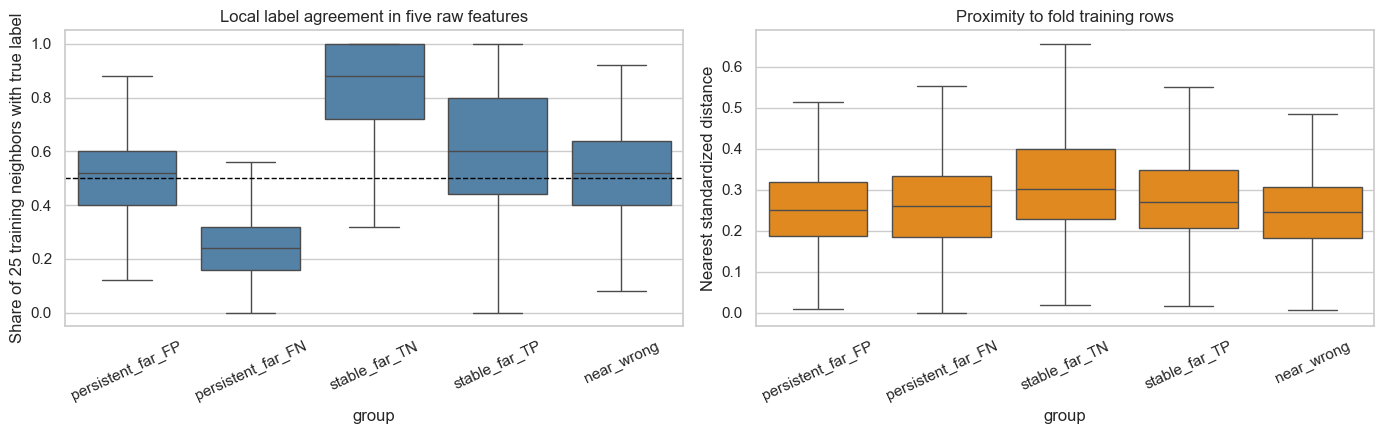

In [7]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

NEIGHBOR_FEATURES=["reports_received","friend_network_size","account_age_days",
                   "crosshair_placement","kill_death_ratio"]
outer=RepeatedStratifiedKFold(n_splits=3,n_repeats=2,random_state=SEED)
splits=list(outer.split(train[NEIGHBOR_FEATURES],train[TARGET]))[:3]
errors["group"]="other"
far=errors.margin.abs().ge(.2)
errors.loc[errors.type.eq("FP") & errors.persistent_wrong & far,"group"]="persistent_far_FP"
errors.loc[errors.type.eq("FN") & errors.persistent_wrong & far,"group"]="persistent_far_FN"
errors.loc[errors.type.eq("correct") & ~errors.wrong_r2 & far & errors[TARGET].eq(0),"group"]="stable_far_TN"
errors.loc[errors.type.eq("correct") & ~errors.wrong_r2 & far & errors[TARGET].eq(1),"group"]="stable_far_TP"
errors.loc[errors.wrong_r1 & errors.margin.abs().le(.05),"group"]="near_wrong"
GROUPS=["persistent_far_FP","persistent_far_FN","stable_far_TN","stable_far_TP","near_wrong"]

neighbor_rows=[]
for fold,(fit_idx,valid_idx) in enumerate(splits,1):
    fit_X=train.iloc[fit_idx][NEIGHBOR_FEATURES]
    imputer=SimpleImputer(strategy="median",add_indicator=True)
    scaler=StandardScaler()
    fit_z=scaler.fit_transform(imputer.fit_transform(fit_X))
    finder=NearestNeighbors(n_neighbors=25,algorithm="ball_tree",n_jobs=-1).fit(fit_z)
    valid=errors.iloc[valid_idx]
    for group in GROUPS:
        sample=valid.loc[valid.group.eq(group)].sample(
            n=min(350,int(valid.group.eq(group).sum())),random_state=SEED+fold)
        if sample.empty: continue
        z=scaler.transform(imputer.transform(train.loc[sample.index,NEIGHBOR_FEATURES]))
        distances,positions=finder.kneighbors(z)
        neighbor_cheater_rate=train.iloc[fit_idx][TARGET].to_numpy()[positions].mean(axis=1)
        true_labels=sample[TARGET].to_numpy()
        support_true=np.where(true_labels==1,neighbor_cheater_rate,1-neighbor_cheater_rate)
        neighbor_rows.append(pd.DataFrame({"fold":fold,"group":group,
            "true":true_labels,"support_true":support_true,
            "nearest_distance":distances[:,0],
            "neighbor_majority_agrees_true":support_true>.5}))
neighbors=pd.concat(neighbor_rows,ignore_index=True)
neighbor_summary=(neighbors.groupby("group",observed=True)
                  .agg(sampled=("true","size"),
                       median_neighbor_support_true=("support_true","median"),
                       neighbor_majority_agrees_true=("neighbor_majority_agrees_true","mean"),
                       median_nearest_distance=("nearest_distance","median")))
display(neighbor_summary.round(3))
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
sns.boxplot(data=neighbors,x="group",y="support_true",order=GROUPS,
            showfliers=False,color="steelblue",ax=axes[0])
axes[0].axhline(.5,color="black",linestyle="--",linewidth=1)
axes[0].set(ylabel="Share of 25 training neighbors with true label",
            title="Local label agreement in five raw features")
sns.boxplot(data=neighbors,x="group",y="nearest_distance",order=GROUPS,
            showfliers=False,color="darkorange",ax=axes[1])
axes[1].set(ylabel="Nearest standardized distance",title="Proximity to fold training rows")
for ax in axes: ax.tick_params(axis="x",labelrotation=25)
plt.tight_layout();plt.show()

### Interpretation boundary

This audit samples at most 350 accounts per group per fold and uses only five raw predictors. A near neighbor under this metric may differ on other important features. Treat the summary as a clue for a future targeted experiment, not a label-quality verdict. The saved `eda_error_context_v2` dataset remains the single artifact produced by this notebook.